# 01 · Quickstart: your first Chronos-2 forecast

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/01_quickstart.ipynb)

Companion notebook for *Chronos-2 in Practice (1/5)*.

**What you will learn**

- How to load Chronos-2 on a CPU or a GPU, and what the model gives you out of the box.
- A first probabilistic forecast in about ten lines with `predict_df`: one week of Spanish
  electricity demand, with a median and 80% / 98% prediction bands.
- How to read the fan chart, and how to check one week against what really happened (and why
  one week is not an evaluation).
- What the small checkpoint `autogluon/chronos-2-small` trades for speed.
- Where Chronos-2 stood in the benchmarks of its own paper, and why that snapshot ages fast.

Runtime: < 1 min on a laptop CPU (FAST_MODE: < 1 min), plus a one-time download of the model
and the dataset.

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time
from statistics import median

import pandas as pd
from huggingface_hub.utils import enable_progress_bars
from IPython.display import Image, display
from transformers.utils import logging as transformers_logging

from c2p.config import get_device, get_paths, is_fast_mode, set_seed
from c2p.data import (
    add_calendar_features,
    make_future_frame,
    spain_energy_frame,
    validate_and_prepare,
)
from c2p.eval import BacktestConfig, backtest, coverage_column, evaluate
from c2p.models import CHRONOS2, CHRONOS2_SMALL, Chronos2Forecaster, load_chronos2, parameter_count
from c2p.plots.architecture import chronos2_sizes, plot_architecture
from c2p.plotting import plot_benchmarks, plot_fan, save_figure, set_style
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, INTERVALS, TIMESTAMP_COL

FAST_MODE = is_fast_mode(default=False)  # True: fewer windows/series, runs in a few minutes on CPU
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
# Skip the "Loading weights" widget (GitHub cannot render it) but keep download progress bars.
transformers_logging.disable_progress_bar()
enable_progress_bars()

for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cpu
           fast_mode: False
                seed: 42
          run_at_utc: 2026-10-30 14:28
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 8
                 gpu: none
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


/home/eperez/.claude-science/conda/envs/c2p/lib/python3.11/site-packages/huggingface_hub/utils/tqdm.py:176: UserWarning: Cannot enable progress bars: environment variable `HF_HUB_DISABLE_PROGRESS_BARS=1` is set and has priority.
  warnings.warn(


## 1. Load Chronos-2 on a CPU or a GPU

Chronos-2 is small enough for a laptop CPU; a GPU only matters for many series or low
latency. Where it can run is decided when PyTorch is installed:

| Your machine | Install | Device |
| --- | --- | --- |
| No NVIDIA GPU | `uv sync` (on Linux, `uv sync --extra cpu` is a much smaller download) | `"cpu"` |
| NVIDIA GPU (Windows or Linux) | `uv sync --extra cu130` | `"cuda"` |

Plain `uv sync` installs PyPI's default PyTorch build (CPU-only on Windows and macOS, CUDA on
Linux). `uv run` re-syncs the environment first, so keep passing the extra you installed with
(`uv run --extra cu130 jupyter lab`). In code, the device is the `device_map` argument of
`from_pretrained`; `load_chronos2` passes the one picked by `get_device()` (`"cuda"` when
PyTorch sees a GPU), and the environment variable `C2P_DEVICE=cpu` or `C2P_DEVICE=cuda` forces
a choice.

This notebook is already small: FAST_MODE only times one run instead of several and sends its
outputs to `results/fast/`.

In [3]:
start = time.perf_counter()
pipeline = load_chronos2(CHRONOS2, device=DEVICE)
load_seconds = time.perf_counter() - start

levels = pipeline.quantiles
print(f"Model:            {CHRONOS2} on {pipeline.inner_model.device}")
print(f"Parameters:       {parameter_count(pipeline) / 1e6:.1f} M")
print(f"Load time:        {load_seconds:.1f} s (indicative)")
print(f"Context:          the last {pipeline.model_context_length:,} steps at most")
print(f"Horizon:          up to {pipeline.model_prediction_length:,} steps in one pass")
print(f"Native quantiles: {len(levels)} levels from {min(levels)} to {max(levels)}")

Model:            amazon/chronos-2 on cpu
Parameters:       119.5 M
Load time:        2.1 s (indicative)
Context:          the last 8,192 steps at most
Horizon:          up to 1,024 steps in one pass
Native quantiles: 21 levels from 0.01 to 0.99


### The shape of the model

Those limits are what the diagram below is drawn from. `chronos2_sizes(pipeline)` reads the
context length, the horizon, the patch size, the quantile levels and the encoder shape from the
checkpoint you just loaded, so the figure cannot quietly disagree with the weights; the stages
themselves come from section 3 of the technical report.

Step 4 is what separates Chronos-2 from Chronos-Bolt: every encoder block attends twice, once
along time within one series and once across the series that share a group ID.


Chronos2Sizes(context_length=8192, prediction_length=1024, n_quantiles=21, quantile_low=0.01, quantile_high=0.99, patch_size=16, n_blocks=12, d_model=768)


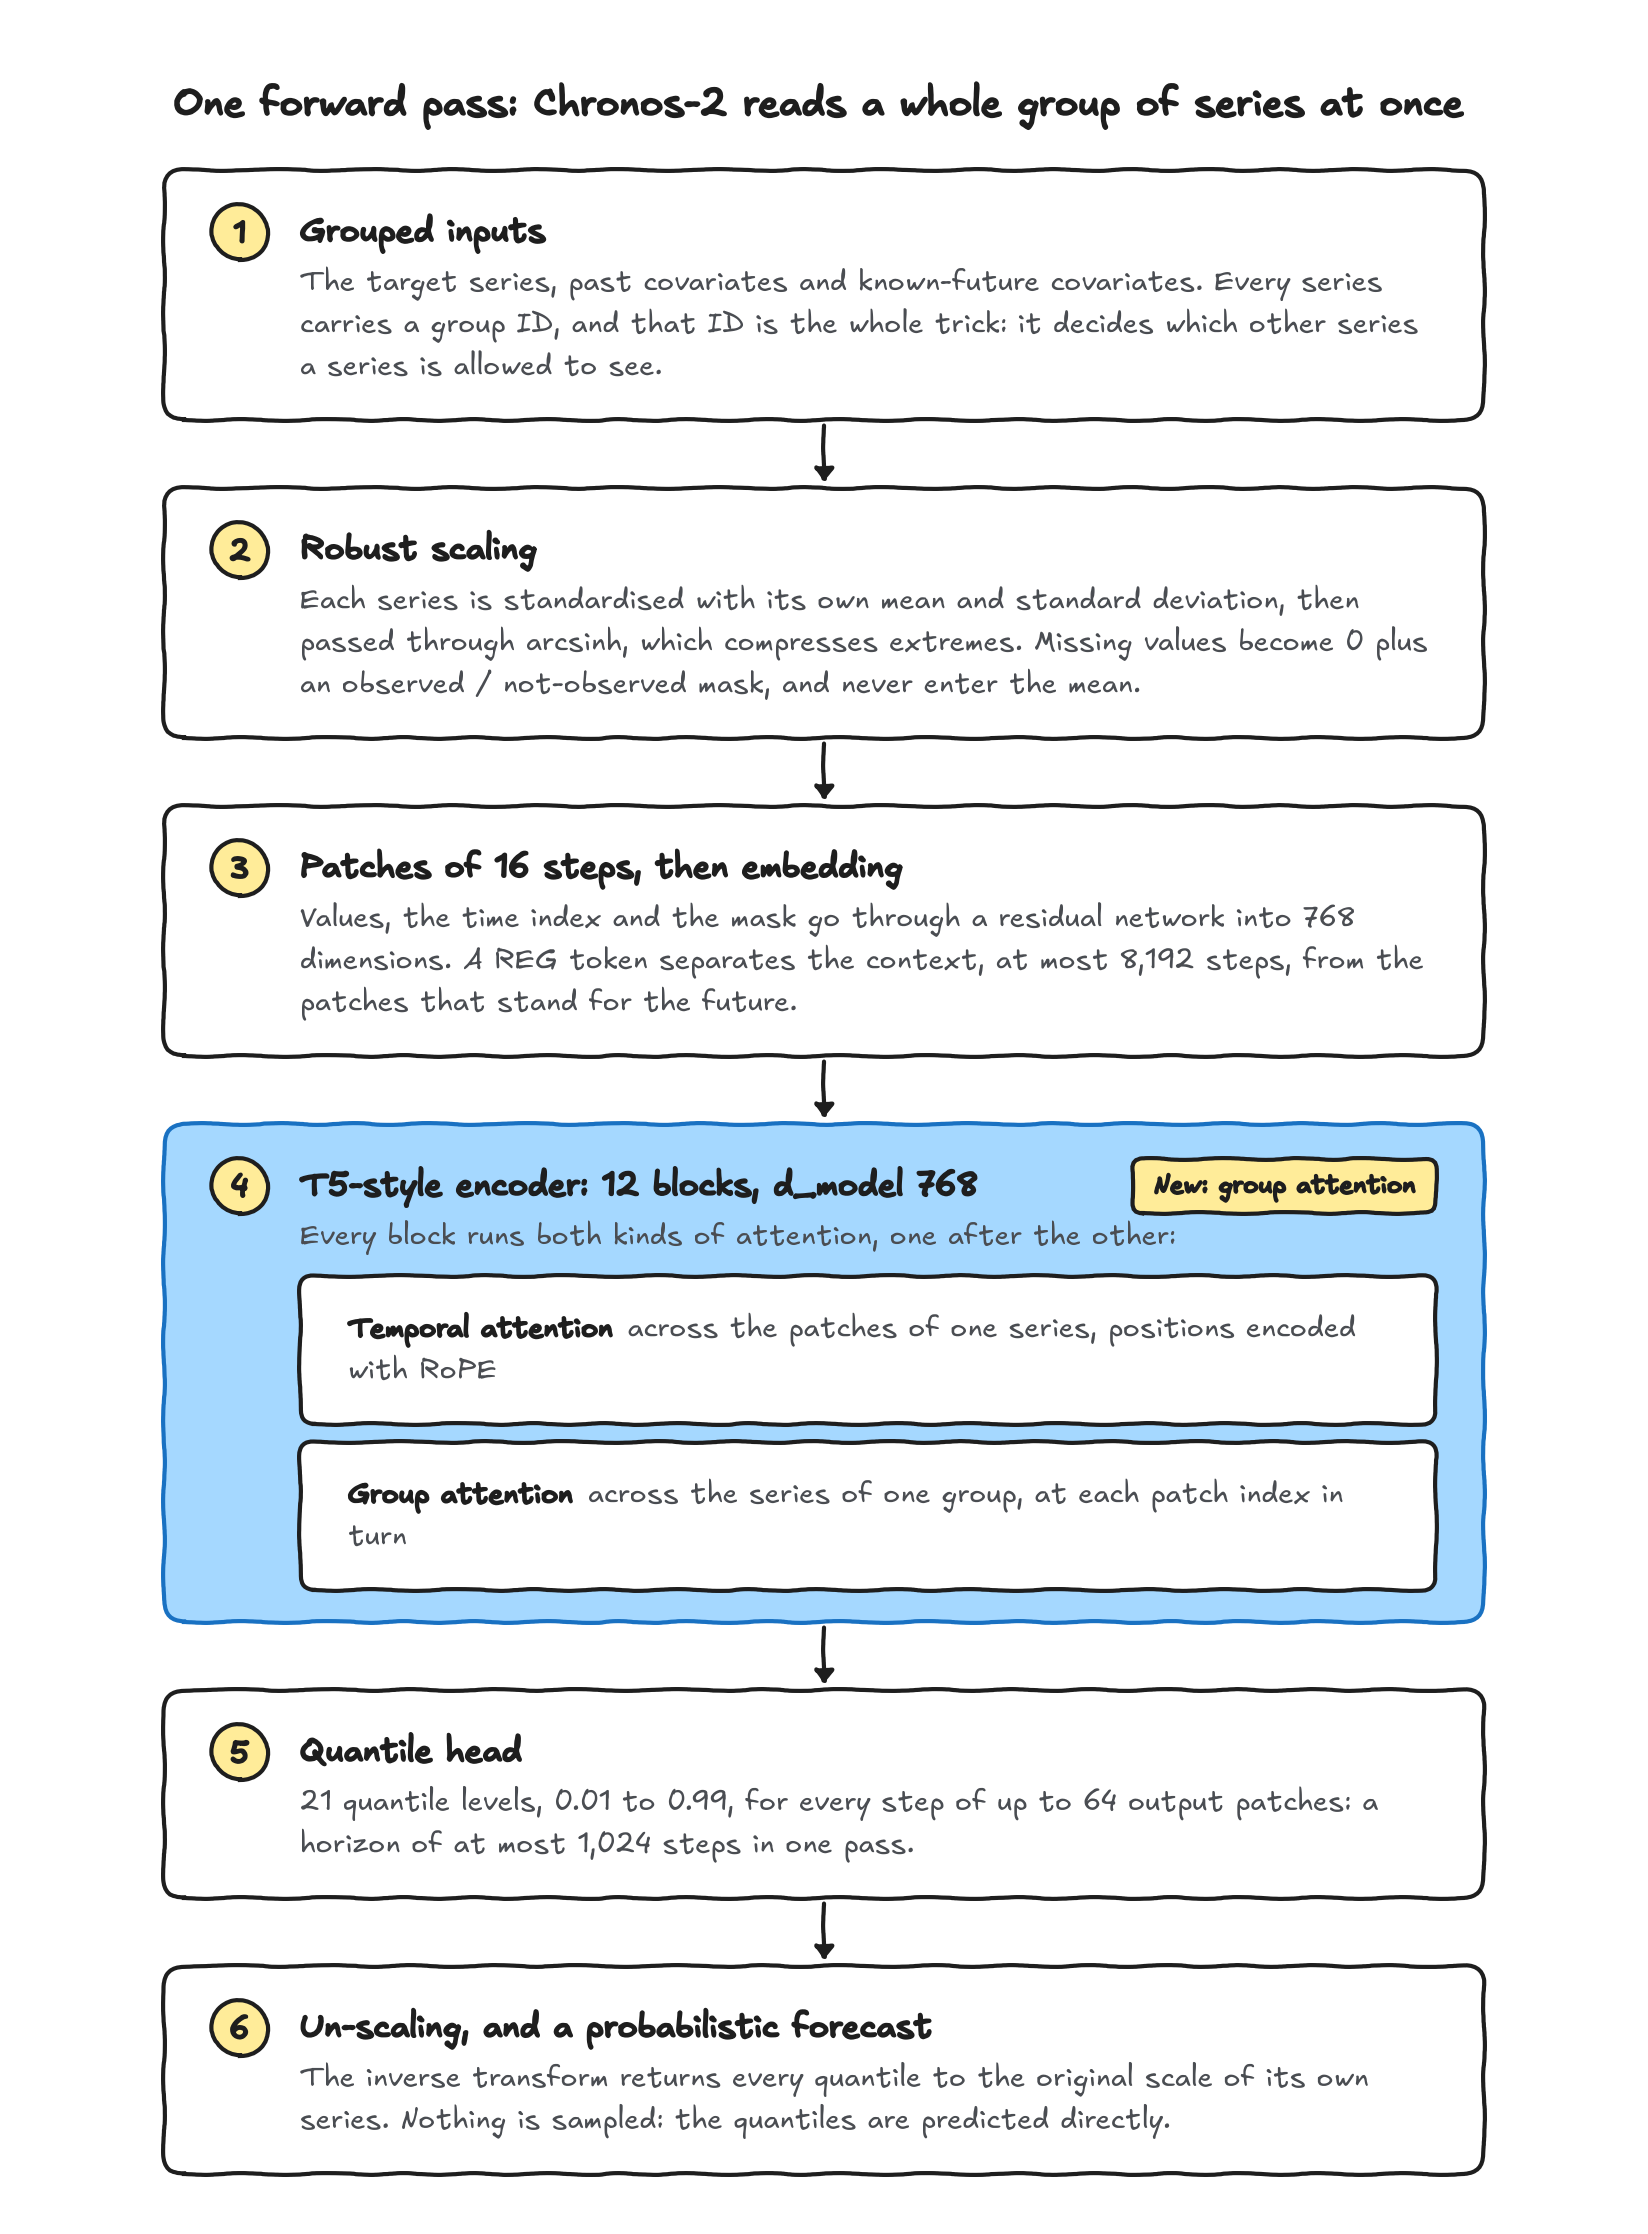

In [4]:
sizes = chronos2_sizes(pipeline)
print(sizes)
fig = plot_architecture(sizes=sizes)
(figure_path,) = save_figure(fig, "01_architecture", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 2. Your first forecast in 10 lines

We forecast the Spanish national electricity load (`load_actual`, in MW) one week ahead,
from all the history before a fixed forecast origin. The data goes through the checklist of
notebook `00_data_checks` first: `validate_and_prepare` returns a regular hourly grid with
timezone-naive UTC timestamps and NaN where a reading is missing (Chronos-2 masks NaN, so
nothing is imputed).

The origin is chosen so that the week is an ordinary one. Timestamps are UTC, and Madrid is
one hour ahead in November, so a cutoff at Sunday 22:00 UTC (23:00 in Madrid) makes the
horizon run exactly from Monday 00:00 to Sunday 23:00, local time. Holiday weeks are a
different problem (demand drops to Sunday levels on a weekday) that needs calendar covariates:
they are left for article 3. The second cell checks the dates and the holidays with the
calendar instead of trusting this paragraph.

In [5]:
TARGET = "load_actual"  # hourly electricity demand in Spain, MW
CUTOFF = pd.Timestamp("2018-11-11 22:00")  # forecast origin, naive UTC (23:00 in Madrid)
HORIZON = 168  # one week of hourly steps
QUANTILES = [0.01, 0.1, 0.5, 0.9, 0.99]  # the median plus the bounds of the 80% and 98% bands

raw = spain_energy_frame()[[ID_COL, TIMESTAMP_COL, TARGET]]
series, report = validate_and_prepare(raw, freq="h", target=TARGET)
print(
    f"{len(series):,} hourly rows, {series[TIMESTAMP_COL].min()} to "
    f"{series[TIMESTAMP_COL].max()} UTC; timestamps inserted: {report.n_missing_timestamps}; "
    f"missing values left as NaN: {report.n_missing_values[TARGET]}"
)

35,064 hourly rows, 2014-12-31 23:00:00 to 2018-12-31 22:00:00 UTC; timestamps inserted: 0; missing values left as NaN: 36


In [6]:
def in_madrid(timestamp: pd.Timestamp) -> str:
    """Show a naive UTC timestamp in Madrid local time."""
    return f"{timestamp.tz_localize('UTC').tz_convert('Europe/Madrid'):%a %Y-%m-%d %H:%M}"


past = series[series[TIMESTAMP_COL] <= CUTOFF]
week_ahead = add_calendar_features(make_future_frame(past, prediction_length=HORIZON, freq="h"))
first, last = week_ahead[TIMESTAMP_COL].iloc[[0, -1]]
n_holidays = int(week_ahead["is_holiday"].sum())
print(f"Forecast origin: {CUTOFF} UTC = {in_madrid(CUTOFF)} in Madrid")
print(f"Horizon:         {first} to {last} UTC = {in_madrid(first)} to {in_madrid(last)}")
print(f"National holidays in the horizon: {n_holidays}")
assert n_holidays == 0, "Pick an ordinary week: holidays need calendar covariates (article 3)."

Forecast origin: 2018-11-11 22:00:00 UTC = Sun 2018-11-11 23:00 in Madrid
Horizon:         2018-11-11 23:00:00 to 2018-11-18 22:00:00 UTC = Mon 2018-11-12 00:00 to Sun 2018-11-18 23:00
National holidays in the horizon: 0


The next cell is all you need in your own project: a long-format frame (one row per
`item_id` and `timestamp`, one column per target), a cutoff, `from_pretrained` and
`predict_df`. It deliberately uses the library directly, not this repository's wrappers.

- `predict_df` infers the frequency from the timestamps and refuses series with missing rows,
  so keep that check: do not pass `freq` unless the grid is verified (see notebook 00).
  Timestamps must be timezone-naive; timezone-aware ones raise an error.
- Chronos-2 reads at most the context length printed above; older history is ignored.
- `quantile_levels` picks the quantiles to return: native levels as predicted, others
  interpolated between them. The `predictions` column is the median.

In [7]:
from chronos import Chronos2Pipeline

pipeline = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)
context = series[series["timestamp"] <= CUTOFF]  # item_id, timestamp, load_actual
forecast = pipeline.predict_df(
    context,
    target=TARGET,
    prediction_length=HORIZON,
    quantile_levels=QUANTILES,
)
forecast.head()

,item_id,timestamp,target_name,predictions,0.01,0.1,0.5,0.9,0.99
0,ES,2018-11-11 23:00:00,load_actual,24268.394531,23393.548828,23982.875000,24268.394531,24704.167969,26171.009766
1,ES,2018-11-12 00:00:00,load_actual,23101.585938,21931.500000,22670.984375,23101.585938,23595.197266,25371.023438
2,ES,2018-11-12 01:00:00,load_actual,22358.017578,21109.892578,21841.605469,22358.017578,22951.218750,25022.076172
3,ES,2018-11-12 02:00:00,load_actual,21986.375000,20570.949219,21415.626953,21986.375000,22751.585938,24953.732422
4,ES,2018-11-12 03:00:00,load_actual,22133.037109,20534.509766,21475.050781,22133.037109,23005.250000,25382.296875


## 3. Save the forecast, then plot it from the file

Every number and figure in the articles comes from a CSV in `results/`. We save the forecast
with the actual load of that week joined *after* forecasting, plus the last two weeks of
context for the chart, and draw the fan chart from the files read back from disk.

In [8]:
HISTORY_HOURS = 14 * 24  # two weeks of context in the fan chart

actuals = series[series[TIMESTAMP_COL] > CUTOFF].rename(columns={TARGET: "actual"})
first_forecast = forecast.merge(actuals, on=[ID_COL, TIMESTAMP_COL], how="left", validate="1:1")
history = context.groupby(ID_COL).tail(HISTORY_HOURS)
for frame, name in [(first_forecast, "01_first_forecast"), (history, "01_first_history")]:
    path = save_results(frame, name, PATHS)
    print(f"Saved {path.relative_to(PATHS.root).as_posix()} ({len(frame)} rows)")

used = min(len(context), pipeline.model_context_length)
print(f"Context: {len(context):,} hours available, the model read the last {used:,}")

Saved results/01_first_forecast.csv (168 rows)
Saved results/01_first_history.csv (336 rows)
Context: 33,864 hours available, the model read the last 8,192


How to read the fan chart: the black line is the history the model saw and the gray line what
really happened. The blue line is the median forecast, the darker band the 80% interval (the
0.1 to 0.9 quantiles) and the lighter band the 98% interval (0.01 to 0.99). Look for three
things: does the median repeat the daily cycle and the weekend dip, do the bands widen where
demand is harder to predict, and does the actual load stay inside the bands most of the time?

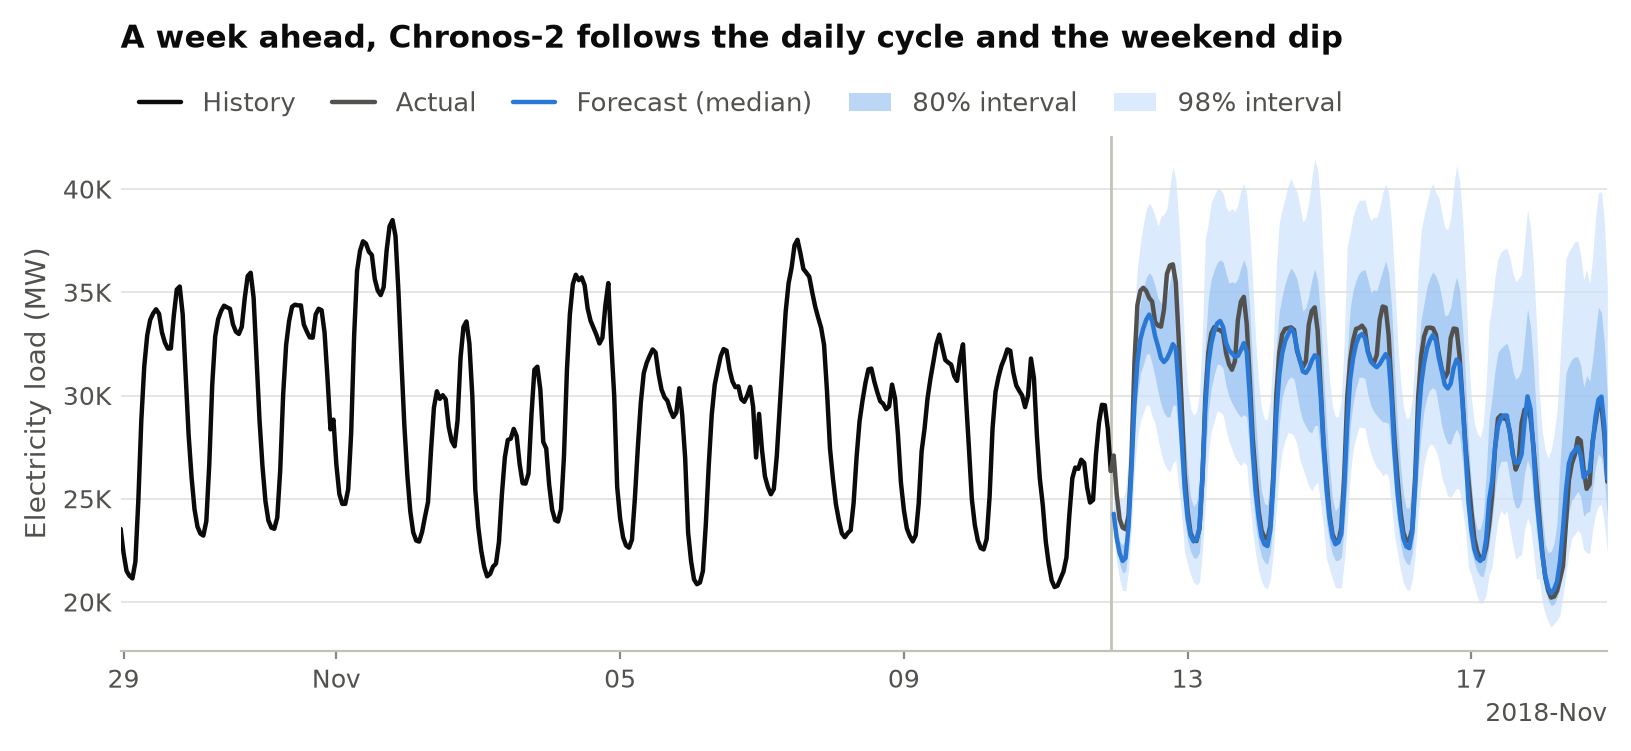

In [9]:
saved = load_results("01_first_forecast", PATHS)
ax = plot_fan(
    load_results("01_first_history", PATHS),
    saved,
    actuals=saved.rename(columns={"actual": TARGET}),
    target=TARGET,
    history=HISTORY_HOURS,
    freq="h",
    title="A week ahead, Chronos-2 follows the daily cycle and the weekend dip",
    ylabel="Electricity load (MW)",
)
(figure_path,) = save_figure(ax.figure, "01_fan_chart", PATHS.figures)
display(Image(filename=figure_path, width=800))

### How good was that week? (one week, not an evaluation)

A single week is an anecdote: article 2 backtests many forecast origins against baselines.
Still, the numbers should make sense:

- **MAE** of the median, in MW, also shown relative to the mean load (WAPE).
- **WQL**, the weighted quantile loss: the quantile loss averaged over the nine deciles and
  divided by the total load. It is the probabilistic metric of fev-bench and of the Chronos-2
  paper; lower is better.
- **Coverage**: the share of hours whose actual load falls inside the 80% and 98% bands. Good
  bands cover about their nominal share over many weeks; a single week can be off either way.

`c2p.eval` scores the nine deciles, like fev-bench, but the 10-line cell asked for five
levels. So the same model runs again through the backtest harness of article 2, with one
window ending at the same cutoff: it gets exactly the same context, the actuals are joined
only after it has answered, and the levels both runs share must come out identical (checked
below).

In [10]:
WEEK_CONFIG = BacktestConfig(
    prediction_length=HORIZON, n_windows=1, freq="h", season_length=24, target=TARGET
)
week = series[series[TIMESTAMP_COL] <= CUTOFF + pd.Timedelta(hours=HORIZON)]  # ends with it
TIMING_RUNS = 1 if FAST_MODE else 5


def forecast_week(forecaster: Chronos2Forecaster) -> pd.DataFrame:
    """Forecast the week after CUTOFF with the backtest harness (one window, actuals joined).

    ``seconds`` is the median time of ``TIMING_RUNS`` identical runs after a warm-up call,
    which pays one-off setup costs.
    """
    backtest(forecaster, week, WEEK_CONFIG)
    runs = [backtest(forecaster, week, WEEK_CONFIG) for _ in range(TIMING_RUNS)]
    return runs[0].assign(seconds=median(run["seconds"].iloc[0] for run in runs))


def score_week(forecasts: pd.DataFrame) -> pd.DataFrame:
    """fev metrics and band coverage of the week, plus the MAE of the median."""
    mae = (forecasts["predictions"] - forecasts["actual"]).abs().mean()
    return evaluate(forecasts, week, WEEK_CONFIG).assign(MAE=mae)

In [11]:
week_forecasts = forecast_week(Chronos2Forecaster(pipeline))
shared = [str(level) for level in QUANTILES]
pd.testing.assert_frame_equal(week_forecasts[shared], saved[shared], rtol=1e-5)
path = save_results(score_week(week_forecasts), "01_first_forecast_metrics", PATHS)
print(f"Saved {path.relative_to(PATHS.root).as_posix()}")

Saved results/01_first_forecast_metrics.csv


In [12]:
metrics = load_results("01_first_forecast_metrics", PATHS).iloc[0]
n_hours = int(load_results("01_first_forecast", PATHS)["actual"].notna().sum())
print(f"One week ({in_madrid(first)} to {in_madrid(last)}), not an evaluation (see article 2):")
print(f"  MAE of the median: {metrics['MAE']:,.0f} MW ({metrics['WAPE']:.1%} of the mean load)")
print(f"  WQL:               {metrics['WQL']:.4f}")
for level in INTERVALS:
    coverage = metrics[coverage_column(level)]
    print(f"  {level:.0%} band held {coverage:.1%} of {n_hours} hours (nominal {level:.0%})")

One week (Mon 2018-11-12 00:00 to Sun 2018-11-18 23:00), not an evaluation (see article 2):
  MAE of the median: 811 MW (2.8% of the mean load)
  WQL:               0.0261
  80% band held 91.7% of 168 hours (nominal 80%)
  98% band held 99.4% of 168 hours (nominal 98%)


## 4. Optional: the small checkpoint

`autogluon/chronos-2-small` is a smaller Chronos-2 checkpoint with the same API: load it with
`load_chronos2(CHRONOS2_SMALL)` or `Chronos2Pipeline.from_pretrained("autogluon/chronos-2-small")`.
It is meant to load and predict faster, which helps on a weak CPU or with many series, at some
cost in accuracy; the cells below measure both on the same week. The prediction time is the
median of a few runs after a warm-up call, on a machine that may be busy with other work, so
treat the timings as indicative (article 5 benchmarks latency and throughput properly). The
WQL is again one week only.

In [13]:
start = time.perf_counter()
small = load_chronos2(CHRONOS2_SMALL, device=DEVICE)
small_load_seconds = time.perf_counter() - start
small_forecasts = forecast_week(Chronos2Forecaster(small, name="chronos-2-small"))


def size_and_speed(
    model_id: str, model: Chronos2Pipeline, load_s: float, forecasts: pd.DataFrame
) -> dict[str, object]:
    """One row of the comparison: size, indicative timings and WQL on the week."""
    return {
        "model": model_id,
        "device": DEVICE,
        "params_m": parameter_count(model) / 1e6,
        "load_s": load_s,
        "predict_s": forecasts["seconds"].iloc[0],
        "WQL": score_week(forecasts)["WQL"].iloc[0],
    }


comparison = pd.DataFrame(
    [
        size_and_speed(CHRONOS2, pipeline, load_seconds, week_forecasts),
        size_and_speed(CHRONOS2_SMALL, small, small_load_seconds, small_forecasts),
    ]
)
path = save_results(comparison, "01_small_vs_base", PATHS)
print(f"Saved {path.relative_to(PATHS.root).as_posix()}")
del small  # free the memory (it matters on a GPU)

Saved results/01_small_vs_base.csv


In [14]:
comparison = load_results("01_small_vs_base", PATHS).set_index("model")
print(comparison.round(4).to_string())
base, small_row = comparison.loc[CHRONOS2], comparison.loc[CHRONOS2_SMALL]
print(
    f"\n{CHRONOS2_SMALL}: {base['params_m'] / small_row['params_m']:.1f}x fewer parameters, "
    f"{base['predict_s'] / small_row['predict_s']:.1f}x faster to predict (indicative, "
    f"{small_row['device']}), WQL {small_row['WQL'] / base['WQL'] - 1:+.0%} on this one week."
)

                          device  params_m  load_s  predict_s     WQL
model                                                                
amazon/chronos-2             cpu  119.4777  2.0560     0.3042  0.0261
autogluon/chronos-2-small    cpu   27.9346  0.6981     0.0926  0.0365

autogluon/chronos-2-small: 4.3x fewer parameters, 3.3x faster to predict (indicative, cpu), WQL +40% on this one week.


## 5. Where Chronos-2 stood in its paper

The Chronos-2 technical report (Ansari et al., 2025, [arXiv:2510.15821](https://arxiv.org/abs/2510.15821))
compares pretrained forecasting models on three benchmarks: fev-bench, GIFT-Eval and Chronos
Benchmark II. The scores are skill scores against Seasonal Naive (which repeats the last
season), in percent: one minus the geometric mean, over the benchmark's tasks, of the model's
error divided by Seasonal Naive's error. Higher is better and zero means "no better than
Seasonal Naive". The error is the scaled quantile loss on fev-bench and the WQL on the other
two, so the panels are not comparable with each other, nor with the one-week WQL above. The
values are copied with their source into `data/reference/paper_benchmarks.csv`; the figure
title below is computed from that file and checked, so it cannot drift from the data.

Leaderboards have moved since the paper: newer models such as TimesFM-3 and t0-gamma claim
higher scores. Check the live leaderboards ([fev-bench](https://huggingface.co/spaces/autogluon/fev-bench),
[GIFT-Eval](https://huggingface.co/spaces/Salesforce/GIFT-Eval)) before quoting a ranking, and
date the snapshot you quote.

In [15]:
def lead_over_runner_up(scores: pd.DataFrame) -> pd.DataFrame:
    """Per benchmark: the best model, the best of the others and the gap in points."""
    rows = []
    for benchmark, group in scores.groupby("benchmark", sort=False):
        ranked = group.sort_values("skill_score_pct", ascending=False)
        top_two = ranked[["model", "skill_score_pct"]].head(2).itertuples(index=False)
        (leader, top), (runner_up, second) = top_two
        rows.append(
            {
                "benchmark": benchmark,
                "leader": leader,
                "leader_score": top,
                "runner_up": runner_up,
                "runner_up_score": second,
                "lead_points": round(top - second, 1),
            }
        )
    return pd.DataFrame(rows)


paper = pd.read_csv(PATHS.data_reference / "paper_benchmarks.csv")
path = save_results(lead_over_runner_up(paper), "01_paper_benchmark_leads", PATHS)
print(f"Saved {path.relative_to(PATHS.root).as_posix()}")

Saved results/01_paper_benchmark_leads.csv


                         leader  leader_score    runner_up  runner_up_score  lead_points
benchmark                                                                               
fev-bench             Chronos-2          47.3        TiRex             42.6          4.7
GIFT-Eval             Chronos-2          51.4  TimesFM-2.5             51.0          0.4
Chronos Benchmark II  Chronos-2          46.6  TimesFM-2.5             42.4          4.2


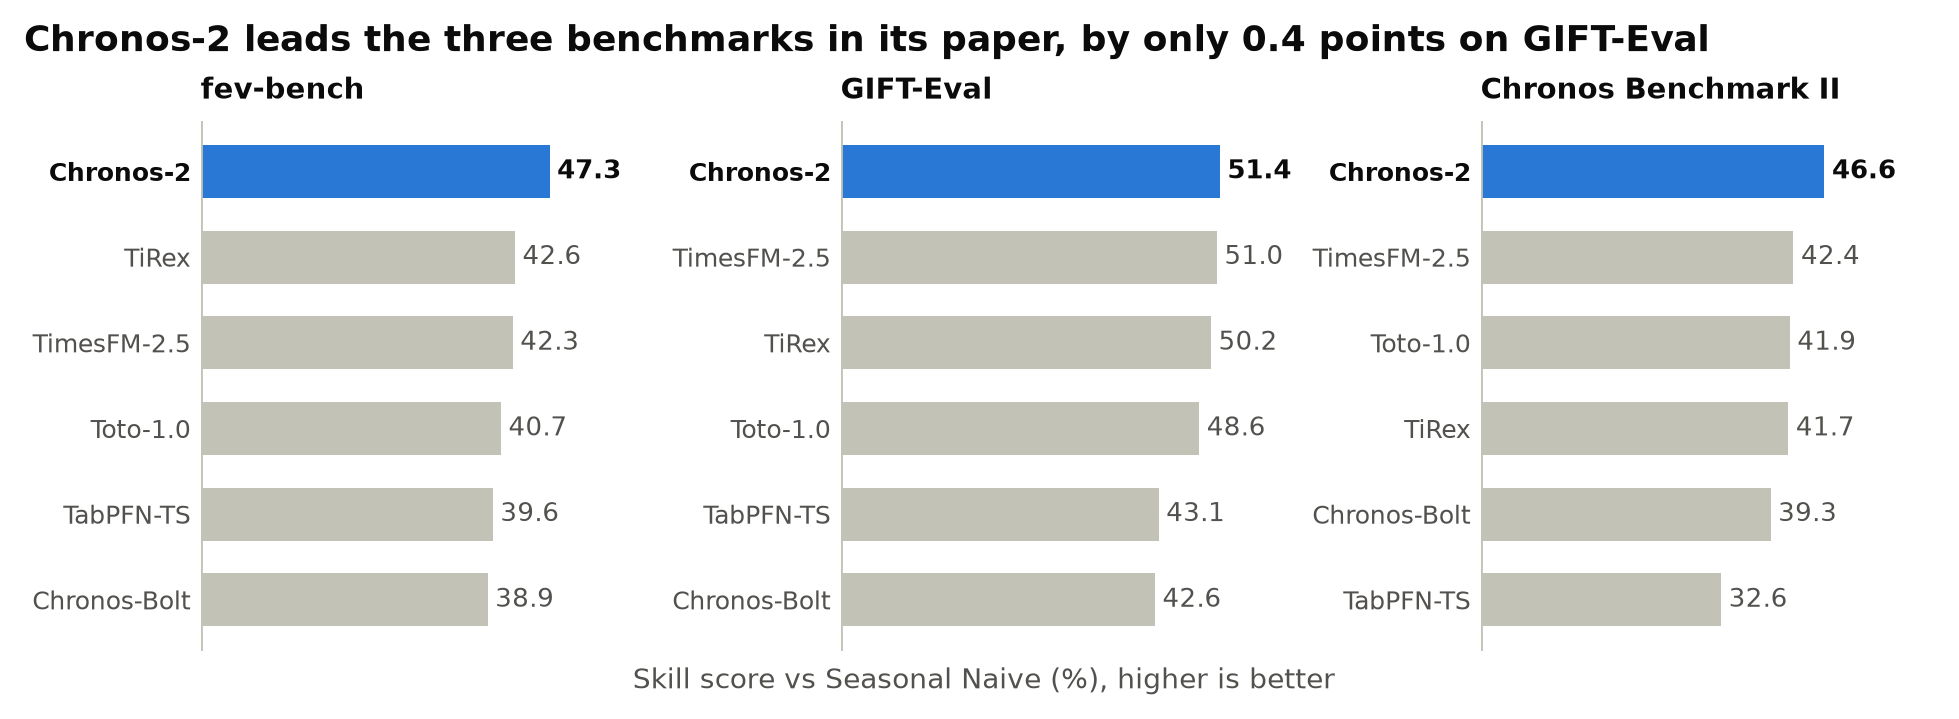

In [16]:
leads = load_results("01_paper_benchmark_leads", PATHS).set_index("benchmark")
closest = leads["lead_points"].idxmin()
gap = leads.loc[closest, "lead_points"]
# The title is checked against the data, so a changed CSV cannot leave a stale title behind.
assert len(leads) == 3 and (leads["leader"] == "Chronos-2").all(), leads
assert closest == "GIFT-Eval" and gap == 0.4, leads
title = f"Chronos-2 leads the three benchmarks in its paper, by only {gap:.1f} points on {closest}"

fig = plot_benchmarks(paper, highlight="Chronos-2", title=title)
(figure_path,) = save_figure(fig, "01_paper_benchmarks", PATHS.figures)
display(Image(filename=figure_path, width=800))
print(leads.to_string())

## Summary

- Chronos-2 runs on a laptop CPU with no training: `from_pretrained` plus `predict_df` on a
  long-format frame is the whole API for a first forecast. It reads only the most recent part
  of a long history (its context length); older rows are ignored.
- It returns quantiles, not just a line: the bands are the part to read, and to check.
- One week can look good and still prove little. Article 2 replaces it with a rolling-origin
  backtest against baselines.
- The small checkpoint is lighter and faster but less accurate on this week; whether that trade
  pays off is a question for a proper backtest (article 2) and benchmark (article 5).

**Next:** [`02_evaluation`](02_evaluation.ipynb) (article 2): an evaluation you can trust,
with many forecast origins, baselines and skill scores.

In [17]:
metrics = load_results("01_first_forecast_metrics", PATHS).iloc[0]
comparison = load_results("01_small_vs_base", PATHS).set_index("model")
leads = load_results("01_paper_benchmark_leads", PATHS).set_index("benchmark")
base, small_row = comparison.loc[CHRONOS2], comparison.loc[CHRONOS2_SMALL]

print(f"Chronos-2: {base['params_m']:.1f} M parameters, loaded in {base['load_s']:.1f} s")
print(
    f"First week: MAE {metrics['MAE']:,.0f} MW, WQL {metrics['WQL']:.4f}, coverage "
    f"{metrics['coverage_80']:.0%} (80% band) and {metrics['coverage_98']:.0%} (98% band)"
)
print(
    f"Small checkpoint: {small_row['params_m']:.1f} M parameters, WQL {small_row['WQL']:.4f} "
    f"vs {base['WQL']:.4f}, predict {small_row['predict_s']:.2f} s vs {base['predict_s']:.2f} s"
)
for benchmark, row in leads.iterrows():
    lead = f"+{row['lead_points']:.1f} points over {row['runner_up']}"
    print(f"Paper, {benchmark}: {row['leader']} {lead}")
print("\nNext: 02_evaluation.ipynb (article 2)")

Chronos-2: 119.5 M parameters, loaded in 2.1 s
First week: MAE 811 MW, WQL 0.0261, coverage 92% (80% band) and 99% (98% band)
Small checkpoint: 27.9 M parameters, WQL 0.0365 vs 0.0261, predict 0.09 s vs 0.30 s
Paper, fev-bench: Chronos-2 +4.7 points over TiRex
Paper, GIFT-Eval: Chronos-2 +0.4 points over TimesFM-2.5
Paper, Chronos Benchmark II: Chronos-2 +4.2 points over TimesFM-2.5

Next: 02_evaluation.ipynb (article 2)
